## 1. Motivation and model overview

A player in possession must decide not only whether to pass, but **where to direct the ball**. Pass selection models this decision as a probability distribution over potential destinations, conditional on attempting a pass. It is distinct from *pass probability*, which estimates whether a pass to a specified destination will be completed. A destination can be attractive without being safe, and a safe destination need not be frequently selected. These components describe different aspects of the same decision.

The distinction is central to spatial models of football. [Spearman's *Beyond Expected Goals* (2018)](https://static.hudl.com/craft/downloads/SSAC2018_Beyond_Expected_Goals.pdf) places a transition model alongside control and scoring opportunity in a framework for evaluating off-ball attacking opportunities. [Fernández, Bornn and Cervone (2021)](https://doi.org/10.1007/s10994-021-05989-6) explicitly model pass selection as a normalized spatial probability surface within an expected-possession-value framework. PRESS follows this probabilistic interpretation of destination choice, while learning the utility of each destination using gradient-boosted trees instead of a convolutional network.

At each observed passing decision, the pitch is discretized into candidate destinations on a **one-metre grid**. The observed endpoint is mapped to its nearest cell centre. The resulting probabilities sum to one across the complete candidate set; they are conditional on a pass being attempted, irrespective of whether the observed pass was successful.


## 2. Probabilistic destination-choice model

Let $s_i$ denote the tracked game state at passing decision $i$, and let $\mathcal G_i$ be its set of candidate destination cells. Each cell $j$ is represented by features $z_{ij}$ describing the pass and the current spatial configuration. A **single shared function** assigns a utility to each destination:

$$
u_{ij}=f_\theta(z_{ij}).$$

PRESS represents $f_\theta$ as an additive ensemble of XGBoost regression trees. Utilities express relative preference, not pass-completion probabilities. The multinomial-logit model converts them into a categorical distribution:

$$
\boxed{p_{ij}=P(Y_i=j\mid s_i,\text{pass})=
\frac{\exp(u_{ij})}{\sum_{k\in\mathcal G_i}\exp(u_{ik})}.}
$$

The normalization couples every candidate in the same decision: changing the utility of one destination changes the probabilities of the others. No separate binary classifier is trained for each cell.

The ensemble is estimated from observed destinations by minimizing the categorical negative log-likelihood,

$$\mathcal L(\theta)=-\sum_i\log p_{i,y_i}(\theta),$$

where $y_i$ is the observed destination cell. The boosting procedure follows the discrete-choice learning approach of [RUMBoost](https://doi.org/10.1016/j.trc.2024.104897), adapted to a shared XGBoost utility ensemble: at each iteration, derivatives of the choice likelihood with respect to the current utilities are used to construct a new tree. Technical details of the gradient, curvature approximation, regularization, model selection and validation are given in the [benchmark](../../benchmarks/03_pass_selection.qmd); see also [Chen and Guestrin (2016)](https://arxiv.org/abs/1603.02754).

After fitting, a scalar temperature $T$ calibrates the predicted distribution,

$$p_{ij}^{(T)}=\frac{p_{ij}^{1/T}}{\sum_k p_{ik}^{1/T}},$$

without changing the ordering of destinations. The installed model uses the flat multinomial-logit specification; an exploratory cross-nested extension is evaluated separately in the benchmark.

## 3. Model features

The utility model uses **19 numerical predictors** and two categorical context variables. All are computed from information available at the passing decision; the realized receiver, pass outcome and subsequent events are excluded.

| Feature group | Predictors | Interpretation |
|---|---|---|
| Pass geometry and carrier motion | Pass distance; signed pass angle relative to carrier velocity; carrier speed | Spatial and kinematic properties of the candidate pass |
| Pitch control | Raw attacking pitch control at the target | Availability of the destination to the attacking team |
| Expected threat (xT) | Own-team and opponent xT at the carrier and target | Spatial estimates of the value of ball possession at the current and candidate locations |
| Defensive structure | Own and opponent pressure-line indices at the carrier and target | Position relative to three ordered longitudinal line centres, following Fernández et al. (2021) |
| Ball retention | One-second ball-drive loss probability | Risk associated with retaining the ball rather than passing |
| Match context | Match minute; score difference known at the decision | Temporal and match-state context |
| Player positioning | Numbers of teammates and opponents beyond the transverse line through the carrier and through the target | Current team and opponent distribution in the attacking direction |
| Categorical context | Possession start type; previous action | Event-based context, one-hot encoded using the vocabulary learned during fitting |

For the four player counts, *beyond* means further toward the **carrier team's opposing goal**, using that attacking direction for both rosters. The carrier is excluded from teammate counts, tracked goalkeepers are retained, and players exactly on the transverse line are not counted. Counts are evaluated separately at the carrier and at each candidate target; they are not restricted to the segment between them. Pressure-line indices identify the nearest of three ordered line centres. Pitch control is used in its raw, uncalibrated form for the choice utility.

**Expected threat.** The xT features follow the expected-threat framework introduced by [Singh (2018), *Introducing Expected Threat (xT)*](https://karun.in/blog/expected-threat.html). They describe the spatial value of possession from each team's perspective, evaluated both at the carrier and at the proposed destination. The calculation used in PRESS is documented in the [Expected Threat vignette](../extras/expected_threat/11_expected_threat.ipynb).

**Pressure lines.** Following the spatial line representation used by [Fernández, Bornn and Cervone (2021)](https://link.springer.com/article/10.1007/s10994-021-05989-6), the model characterizes the positions of the teams' longitudinal lines. For each team, the pressure-line index records which of three ordered line centres is closest to the carrier or candidate destination. This captures whether a potential pass moves the ball across the teams' positional structure.

**Event context.** *Possession start type* is derived from SkillCorner's dynamical events and identifies how the action began, for example through a pass or an interception. *Previous action* identifies the immediately preceding segment: it can be a ball drive or the start type of the action when no preceding ball-drive segment is defined. These labels follow the segmentation conventions described in [Possessions and checkpoints](../06_possession_and_checkpoint_setup/06_possession_and_checkpoint_setup.ipynb).

## 4. Feature importance

The following results summarize **training split-gain importance** for the fitted full-data model, together with each feature's rank across the five held-out evaluation fits. Gain is an attribution of the ensemble's split improvements, not a causal effect or a measure of how predictions would change if a feature were removed.

| Feature | Full-data gain share | Rank across five folds |
|---|---:|---:|
| Pass distance | 34.44% | 1–1 |
| Raw target pitch control | 20.91% | 2–2 |
| Pass angle | 14.41% | 3–3 |
| Teammates beyond target | 5.72% | 4–4 |
| Opponents beyond target | 5.04% | 5–7 |
| Carrier speed | 3.49% | 5–6 |

Distance, pitch control and angle account for **69.76%** of full-data split gain (rounded component shares) and occupy the same first three positions in every fold. This is consistent with geometry and destination accessibility being particularly informative for observed pass choice. Importance does not establish that these variables independently cause the choice.

![Training split-gain allocation for the fitted model and five evaluation folds.](../../figures/feature_importance_pass_selection.png)

## 5. Application to a game state

The following example uses the installed choice model to compute and display a destination-probability surface. It relies on the current tracked state and the prerequisite pitch-control and ball-drive calculations. The supplied demo match and xT inputs are synthetic, and the coarse demonstration grid is used only to keep execution quick; benchmark results use the native one-metre grid. See the [match guide](../../usage.qmd) for loading real tracking data.

model: skillcorner_outfield_pass_selection_flat_v3
choice probabilities: [2.92238475e-06 6.15794521e-06 2.93837137e-05 3.09251105e-04
 7.60162969e-04 2.71408984e-03 3.17493515e-04 5.05744314e-04
 2.65598671e-04 4.65507126e-04 8.14435704e-04 2.04136964e-04
 1.40745116e-05 2.71449614e-06 2.99680840e-05 9.40881834e-05
 2.59695587e-03 6.97840268e-04 1.31827400e-01 9.45660408e-04
 1.70169870e-03 1.09404054e-03 8.93985450e-04 4.93088227e-04
 1.18199868e-04 3.32361171e-05 9.89738414e-06 4.12451060e-05
 2.57731279e-04 3.14997461e-04 1.72652466e-03 9.01715548e-02
 4.53063762e-03 3.16126521e-03 3.54680987e-02 1.34063754e-03
 1.05485671e-03 2.40214163e-04 9.88850444e-05 6.94498804e-06
 2.81146686e-04 4.21994407e-04 6.87307004e-04 1.80714510e-03
 2.82650411e-03 1.66403438e-03 6.25440251e-03 5.14537638e-02
 1.54881607e-03 5.55957478e-04 3.28131906e-04 1.06908638e-04
 8.01176140e-06 3.14976117e-04 2.98373954e-04 1.10235502e-03
 1.63296469e-03 5.64832975e-01 4.25337081e-03 2.51585097e-03
 3.80966117e

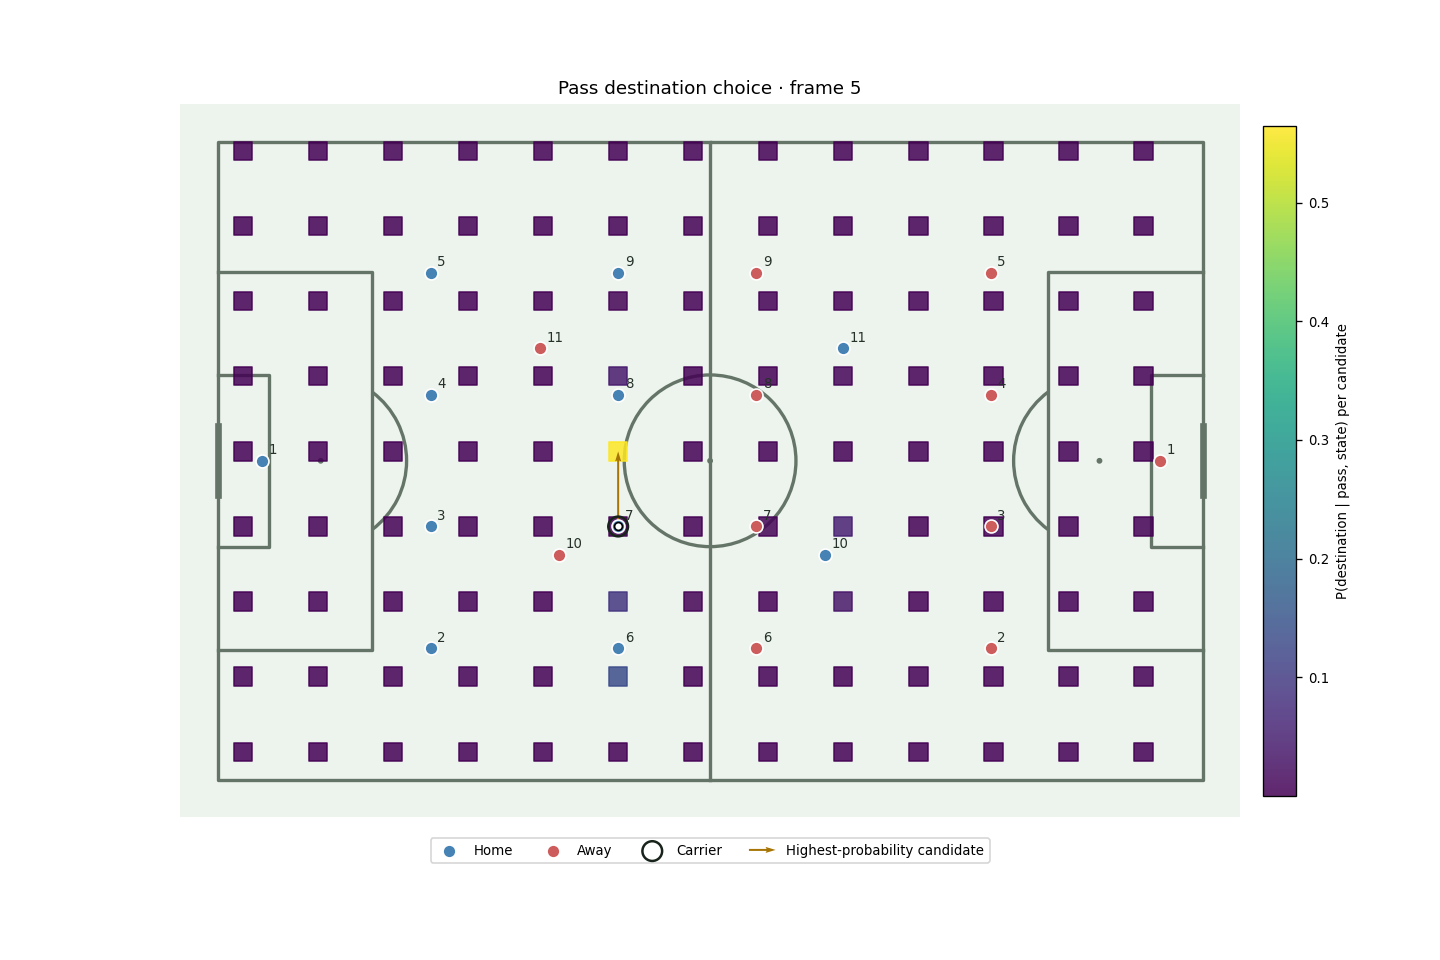

In [5]:
import numpy as np
from pathlib import Path

from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ppcf(frame_id, r_max=80, step=8)
model.compute_ball_drive_loss(frame_id)
model.compute_transition_probabilities(frame_id, xT_grid, match_clock_min=0.5, score_difference_prefix=0)
result = model.get_ppcf_result(frame_id)
print("model:", result["transition_model_id"])
print("choice probabilities:", np.asarray(result["Transition probabilities"]))
print("probability sum:", float(np.sum(result["Transition probabilities"])))

from PRESS.visualization import plot_transition
fig, ax = plot_transition(model, frame_id)
out = Path("figures/vignette_03_transition_pitch.png")
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))


The plotted surface is a **conditional distribution of pass destinations**, not a completion-probability surface. The sum of its cell probabilities should equal one. The example uses the fitted utility model rather than re-estimating it.

## 6. Using the fitted model

The model can also be loaded directly, with its saved feature vocabulary and fitted physical-model dependencies:

```python
from PRESS.model import PassSelectionModel
choice = PassSelectionModel.pretrained()
press = PRESS(tracking, pass_selection_model=choice)
press.compute_ppcf(frame_id)
press.compute_ball_drive_loss(frame_id, t_press=1.0)
probability = press.compute_transition_probabilities(
    frame_id, xT_grid,
    start_type_raw="pass_reception", previous_action_raw="ball_drive",
    match_clock_min=32.5, score_difference_prefix=0,
)
```

Supply the actual contextual values for the selected frame. The positional `xT_grid` argument remains for API compatibility; the installed choice model retains its fitted xT representation. The [benchmark](../../benchmarks/03_pass_selection.qmd) reports the evaluation protocol, training details, exploratory nested alternative and comparison with [Fernández et al. (2021)](https://doi.org/10.1007/s10994-021-05989-6).